# Chapter 3 · Arbitrage and static replication: interactive demos

Companion to Chapter 3 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/03-arbitrage.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

Notation as in the notes: $S_0$ is the stock price, $B$ the price of the zero-coupon bond paying 1 at $T$
($B=(1+r)^{-T}$ with annual compounding), and $C(K)$ the price of a call with strike $K$.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, Dropdown, FloatSlider, SelectionSlider

from ieor222.arbitrage import find_arbitrages, lognormal_call, replicate_payoff
from ieor222.style import COBALT, GOLD, GREY, INK, PALETTE, use_style

use_style()

## 1. An arbitrage checker for a quoted call-price curve

No-arbitrage forces the call price to satisfy $(S_0-BK)^+\le C(K)\le S_0$ (Proposition 3.10) and, as a function
of the strike, to be nonincreasing, convex, with slopes in $[-B,0]$ (Proposition 3.12). For quotes at finitely many
strikes it is enough to check consecutive strikes, with the stock as the call of strike $0$. Apart from one boundary
case, quotes that pass these checks are arbitrage-free in at least one model (Proposition 3.14).

`find_arbitrages` runs the checks. For every violated relation it returns a portfolio of the bond, the stock and the
calls whose payoff is nonnegative in every state, and the cash it collects today. Below, the quotes come from an
arbitrage-free curve (the lognormal model of Chapter 6), and one quote has been moved by hand.

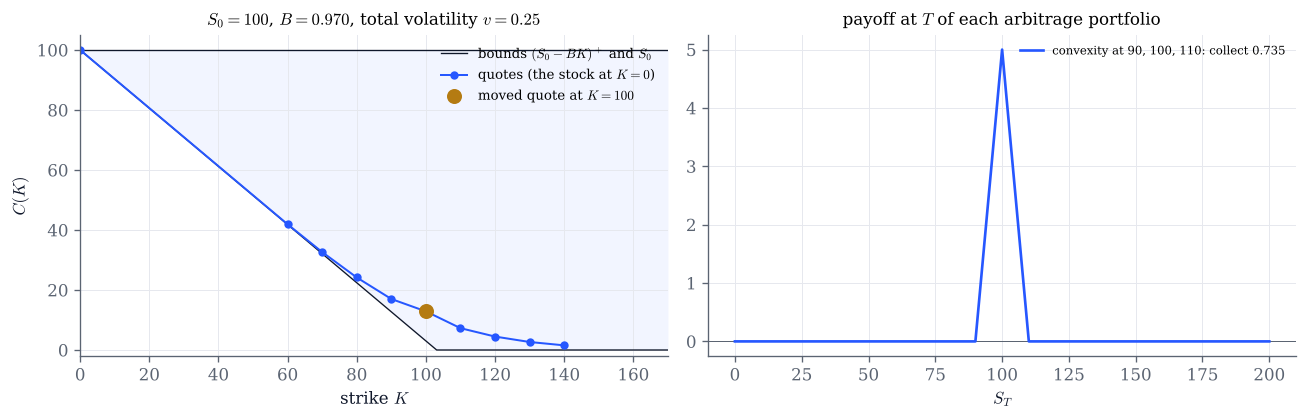

convexity at K = 90, 100, 110: collect 0.735 today; hold +0.5 call(90), -1 call(100), +0.5 call(110)


In [2]:
STRIKES = np.arange(60.0, 141.0, 10.0)

def checker(strike=100.0, bump=1.5, v=0.25, B=0.97, S0=100.0):
    K = STRIKES
    c = lognormal_call(S0, B, K, v)
    i = int(np.argmin(np.abs(K - strike)))
    c[i] += bump
    found = find_arbitrages(S0, B, K, c)

    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
    grid = np.linspace(0, 170, 400)
    lower = np.maximum(S0 - B * grid, 0)
    ax.fill_between(grid, lower, S0, color=COBALT, alpha=0.06, lw=0)
    ax.plot(grid, lower, color=INK, lw=0.8, label="bounds $(S_0-BK)^+$ and $S_0$")
    ax.axhline(S0, color=INK, lw=0.8)
    ax.plot(np.r_[0.0, K], np.r_[S0, c], "o-", color=COBALT, ms=4, lw=1.2,
            label="quotes (the stock at $K=0$)")
    ax.plot(K[i], c[i], "o", color=GOLD, ms=8, label=f"moved quote at $K={K[i]:g}$")
    ax.set(xlim=(0, 170), ylim=(min(-2, c.min() - 2), S0 + 5), xlabel="strike $K$",
           ylabel="$C(K)$", title=f"$S_0={S0:g}$, $B={B:.3f}$, total volatility $v={v:g}$")
    ax.legend(fontsize=8, loc="upper right")

    x = np.linspace(0, 200, 801)
    ax2.axhline(0, color=GREY, lw=0.6)
    if found:
        for a, color in zip(found, PALETTE * 3):
            ks = ", ".join(f"{k:g}" for k in a.strikes)
            ax2.plot(x, a.portfolio.payoff(x), color=color, lw=1.6,
                     label=f"{a.condition} at {ks}: collect {a.profit:.3f}")
        ax2.legend(fontsize=7, loc="upper right")
        ax2.set(title="payoff at $T$ of each arbitrage portfolio", xlabel="$S_T$")
    else:
        ax2.text(0.5, 0.5, "no violation: the quotes pass every check", ha="center",
                 transform=ax2.transAxes, color=INK)
        ax2.set(xlabel="$S_T$")
    fig.tight_layout()
    plt.show()
    for a in found:
        print(a)

checker()

In [3]:
# Explore: move one quote up or down and watch which relations break.
interact(checker,
         strike=SelectionSlider(options=[float(k) for k in STRIKES], value=100.0, continuous_update=False, description="strike"),
         bump=FloatSlider(value=1.5, min=-15.0, max=15.0, step=0.1, continuous_update=False, description="bump"),
         v=FloatSlider(value=0.25, min=0.05, max=0.8, step=0.01, continuous_update=False, description="v"),
         B=FloatSlider(value=0.97, min=0.80, max=1.05, step=0.01, continuous_update=False, description="B"),
         S0=FloatSlider(value=100.0, min=60.0, max=140.0, step=1.0, continuous_update=False, description="S0"));

## 2. Static replication with a strip of options

The Carr–Madan formula (Theorem 3.16) writes a smooth payoff as a bond, a forward and a strip of options:

$$f(S_T)=f(\kappa)+f'(\kappa)(S_T-\kappa)+\int_0^\kappa f''(K)\,(K-S_T)^+\,\mathrm dK+\int_\kappa^\infty f''(K)\,(S_T-K)^+\,\mathrm dK .$$

With strikes on a grid of spacing $h$ between $K_{\min}$ and $K_{\max}$, `replicate_payoff` returns the portfolio of
the bond, the stock, puts below $\kappa$ and calls above $\kappa$ that replicates exactly the linear interpolation $f_h$
of $f$ (Lemma 3.15). Its weights are changes of slope, close to $f''(K)\,h$. Inside the grid the error is at most
$h^2\max|f''|/8$; outside, $f_h$ is a linear extrapolation and the error can be large.

<>:46: SyntaxWarning: invalid escape sequence '\k'
<>:46: SyntaxWarning: invalid escape sequence '\k'
/tmp/ipykernel_18656/1621692761.py:46: SyntaxWarning: invalid escape sequence '\k'
  ax.bar([kappa], [at_kappa], width=0.6 * h, color=GREY, label="half put, half call at $\kappa$")


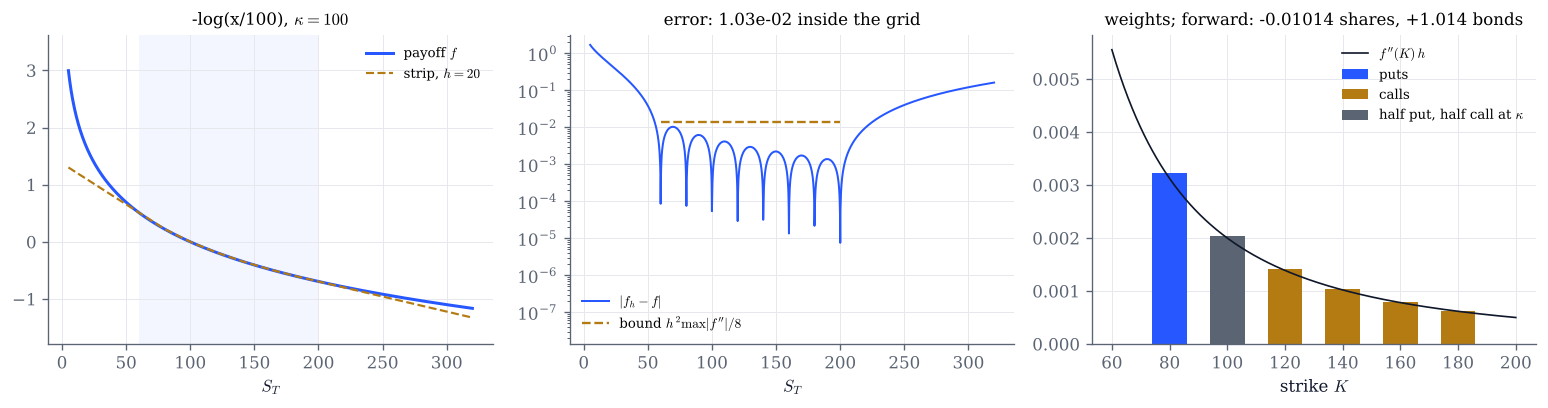

In [4]:
PAYOFFS = {
    "-log(x/100)": (lambda x: -np.log(x / 100), lambda x: 1 / x**2),
    "(x/100)^2": (lambda x: (x / 100) ** 2, lambda x: np.full_like(x, 2 / 100**2)),
    "10 sqrt(x)": (lambda x: 10 * np.sqrt(x), lambda x: -2.5 * x ** -1.5),
}

def strip(payoff="-log(x/100)", h=20.0, k_min=50.0, k_max=200.0, kappa=100.0):
    f, d2f = PAYOFFS[payoff]
    # strikes kappa + j h inside [k_min, k_max] (at least one on each side of kappa)
    lo = min(int(np.ceil((k_min - kappa) / h)), -1)
    hi = max(int(np.floor((k_max - kappa) / h)), 1)
    K = kappa + h * np.arange(lo, hi + 1)
    K = K[K > 0]
    p = replicate_payoff(f, K, kappa)
    x = np.linspace(5, 320, 1600)
    fx, rx = f(x), p.payoff(x)

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    ax = axes[0]
    ax.axvspan(K[0], K[-1], color=COBALT, alpha=0.05, lw=0)
    ax.plot(x, fx, color=COBALT, lw=1.8, label="payoff $f$")
    ax.plot(x, rx, color=GOLD, lw=1.3, ls="--", label=f"strip, $h={h:g}$")
    ax.set(xlabel="$S_T$", title=f"{payoff}, $\\kappa={kappa:g}$")
    pad = 0.15 * (fx.max() - fx.min())
    ax.set_ylim(fx.min() - pad, fx.max() + pad)
    ax.legend(fontsize=8)

    ax = axes[1]
    inside = (x >= K[0]) & (x <= K[-1])
    bound = h**2 * np.max(np.abs(d2f(np.linspace(K[0], K[-1], 2001)))) / 8
    ax.semilogy(x, np.abs(rx - fx) + 1e-16, color=COBALT, lw=1.2, label="$|f_h-f|$")
    ax.hlines(bound, K[0], K[-1], color=GOLD, ls="--", lw=1.4, label="bound $h^2\\max|f''|/8$")
    ax.set(xlabel="$S_T$", ylim=(1e-6 * max(bound, 1e-12), None),
           title=f"error: {np.abs(rx - fx)[inside].max():.2e} inside the grid")
    ax.legend(fontsize=8)

    ax = axes[2]
    ax.set_axisbelow(True)
    puts = sorted((k, w) for k, w in p.puts.items() if k < kappa)
    calls = sorted((k, w) for k, w in p.calls.items() if k > kappa)
    at_kappa = p.puts.get(kappa, 0.0) + p.calls.get(kappa, 0.0)
    if puts:
        ax.bar([k for k, _ in puts], [w for _, w in puts], width=0.6 * h, color=COBALT, label="puts")
    if calls:
        ax.bar([k for k, _ in calls], [w for _, w in calls], width=0.6 * h, color=GOLD, label="calls")
    ax.bar([kappa], [at_kappa], width=0.6 * h, color=GREY, label="half put, half call at $\kappa$")
    kk = np.linspace(K[0], K[-1], 400)
    ax.plot(kk, d2f(kk) * h, color=INK, lw=1.0, label="$f''(K)\\,h$")
    ax.axhline(0, color=GREY, lw=0.6)
    ax.set(xlabel="strike $K$", title=f"weights; forward: {p.stock:+.4g} shares, {p.bond:+.4g} bonds")
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

strip()

In [5]:
# Explore: refine the grid, widen or narrow the range of strikes, change the payoff.
interact(strip,
         payoff=Dropdown(options=list(PAYOFFS), value="-log(x/100)", description="payoff"),
         h=SelectionSlider(options=[50.0, 25.0, 20.0, 10.0, 5.0, 2.5, 1.0], value=20.0,
                           continuous_update=False, description="spacing h"),
         k_min=FloatSlider(value=50.0, min=10.0, max=100.0, step=5.0, continuous_update=False, description="K min"),
         k_max=FloatSlider(value=200.0, min=110.0, max=300.0, step=10.0, continuous_update=False, description="K max"),
         kappa=FloatSlider(value=100.0, min=60.0, max=150.0, step=5.0, continuous_update=False, description="κ"));

## Things to try

- In section 1, raise the quote at $K=100$ little by little. How large must the bump be before a convexity violation
  appears, and how does that threshold relate to the price of the 90/100/110 butterfly on the original curve?
- In section 1, lower the quote at $K=60$ a lot. Which relations break first? Why does a lower bound violation come
  together with a convexity violation involving the stock?
- In section 1, set $B$ above $1$ (a negative interest rate). Which bound changes, and how?
- In section 2, halve $h$ several times and read off how the error inside the grid scales. Then move $K_{\min}$
  towards $0$ for the log payoff: why does the error near small $S_T$ improve so slowly?
- In section 2, choose $10\sqrt{x}$. Why are all the option weights negative?